In [6]:
#Mohammad Amer Khalil
#+963935718668

# 1. Introduction


This project aims to analayze data that was given by a sales company head to find out if there are any interesting patterns relating to the sale frequncy and if there are ways to improve it.

# 2. Data Understanding & Preparation

## 2.1 Data Quality Findings & Cleaning Summary

* **Sparsity & Duplication:** Zero null values and zero duplicated rows were detected in the processed dataset.
* **Data Ranges:** The unit prices and item quantities are positive and clean, with no negative transactional anomalies remaining.
* **Variables:** The data types are correctly aligned (e.g., Float for prices/amounts, objects for categorical metadata).

## 2.2 Data Verification & Summary Statistics

In [7]:
# I will use the CSV that i worked on last homework to start from so the processing is from it
#no need to do the steps again i will just call the processed file

In [8]:
import pandas as pd
df = pd.read_csv('online_retail_task2_students_processed.csv')

In [9]:
print (df.head())

   InvoiceNo StockCode                     Description  Quantity  \
0     536365    84029E  RED WOOLLY HOTTIE WHITE HEART.         6   
1     536366     22633          HAND WARMER UNION JACK         6   
2     536382     21832            CHOCOLATE CALCULATOR        12   
3     536390     22968      ROSE COTTAGE KEEPSAKE BOX          8   
4     536390    84030E   ENGLISH ROSE HOT WATER BOTTLE        24   

           InvoiceDate  UnitPrice  CustomerID         Country  TotalAmount  \
0  2010-12-01 08:26:00       3.39       17850  United Kingdom        20.34   
1  2010-12-01 08:28:00       1.85       17850  United Kingdom        11.10   
2  2010-12-01 09:45:00       1.65       16098  United Kingdom        19.80   
3  2010-12-01 10:19:00       8.50       17511  United Kingdom        68.00   
4  2010-12-01 10:19:00       3.75       17511  United Kingdom        90.00   

  YearMonth  
0   2010-12  
1   2010-12  
2   2010-12  
3   2010-12  
4   2010-12  


In [10]:
print(f'Total rows: {len(df)}')

Total rows: 14526


In [11]:
print(f'Total columns: {len(df.columns)}')
print(f'Columns Names: {df.columns}')

Total columns: 10
Columns Names: Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'TotalAmount', 'YearMonth'],
      dtype='object')


In [12]:
print('Data types:')
df.info()

Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14526 entries, 0 to 14525
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   InvoiceNo    14526 non-null  int64  
 1   StockCode    14526 non-null  object 
 2   Description  14526 non-null  object 
 3   Quantity     14526 non-null  int64  
 4   InvoiceDate  14526 non-null  object 
 5   UnitPrice    14526 non-null  float64
 6   CustomerID   14526 non-null  int64  
 7   Country      14526 non-null  object 
 8   TotalAmount  14526 non-null  float64
 9   YearMonth    14526 non-null  object 
dtypes: float64(2), int64(3), object(5)
memory usage: 1.1+ MB


In [13]:
print('Missing Values:')
print(df.isnull().sum())

Missing Values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalAmount    0
YearMonth      0
dtype: int64


In [14]:
print(f"Number of duplicate rows: {df.duplicated().sum()}")
print(df.duplicated())

Number of duplicate rows: 0
0        False
1        False
2        False
3        False
4        False
         ...  
14521    False
14522    False
14523    False
14524    False
14525    False
Length: 14526, dtype: bool


In [15]:
# Summary statistics for numerical columns
display(df.describe())

,InvoiceNo,Quantity,UnitPrice,CustomerID,TotalAmount
count,14526.000000,14526.000000,14526.000000,14526.000000,14526.000000
mean,560459.389164,12.247281,2.998048,15301.437147,20.424143
std,13108.962404,43.218285,5.628479,1717.054969,61.422612
min,536365.000000,1.000000,0.040000,12347.000000,0.120000
25%,548996.750000,2.000000,1.250000,13959.000000,4.560000
50%,561693.500000,5.000000,1.950000,15194.000000,11.800000
75%,571965.000000,12.000000,3.750000,16813.000000,19.500000
max,581585.000000,2400.000000,300.000000,18283.000000,3035.520000


# 3. Analytical Questions

1. What is the best selling item? and what is the worst selling item?
2. What are the highest and lowest selling months?
3. What is the average price most people buy at/don't buy over?
4. What country has the most amount of sales and what country has the least amount of sales?
5. In the top performing countries what are the popular items being sold?

# 4. Key Performance Indicators (KPIs)

To track and measure our retail performance, we will focus on these three simple metrics:

* **Total Revenue:** Sum of all sales to track total money made.
* **Total Quantity Sold:** Sum of all item quantities sold to check stock movement.
* **Average Unit Price:** Average price per item to see our pricing sweet spot.

# 5. Data Analysis & Visualization

## 5.1 Analyze Best-Selling and Worst-Selling Items

### Question:
What is the best selling item? and what is the worst selling item?

### Analysis:
I will aggregate the data by product description to find the top 10 items and also bottom 10 items by total quantity sold and total revenue.

/tmp/ipykernel_2627/1717904170.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_qty, x='Quantity', y='StockCode', palette='viridis')
/tmp/ipykernel_2627/1717904170.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_rev, x='TotalAmount', y='StockCode', palette='magma')


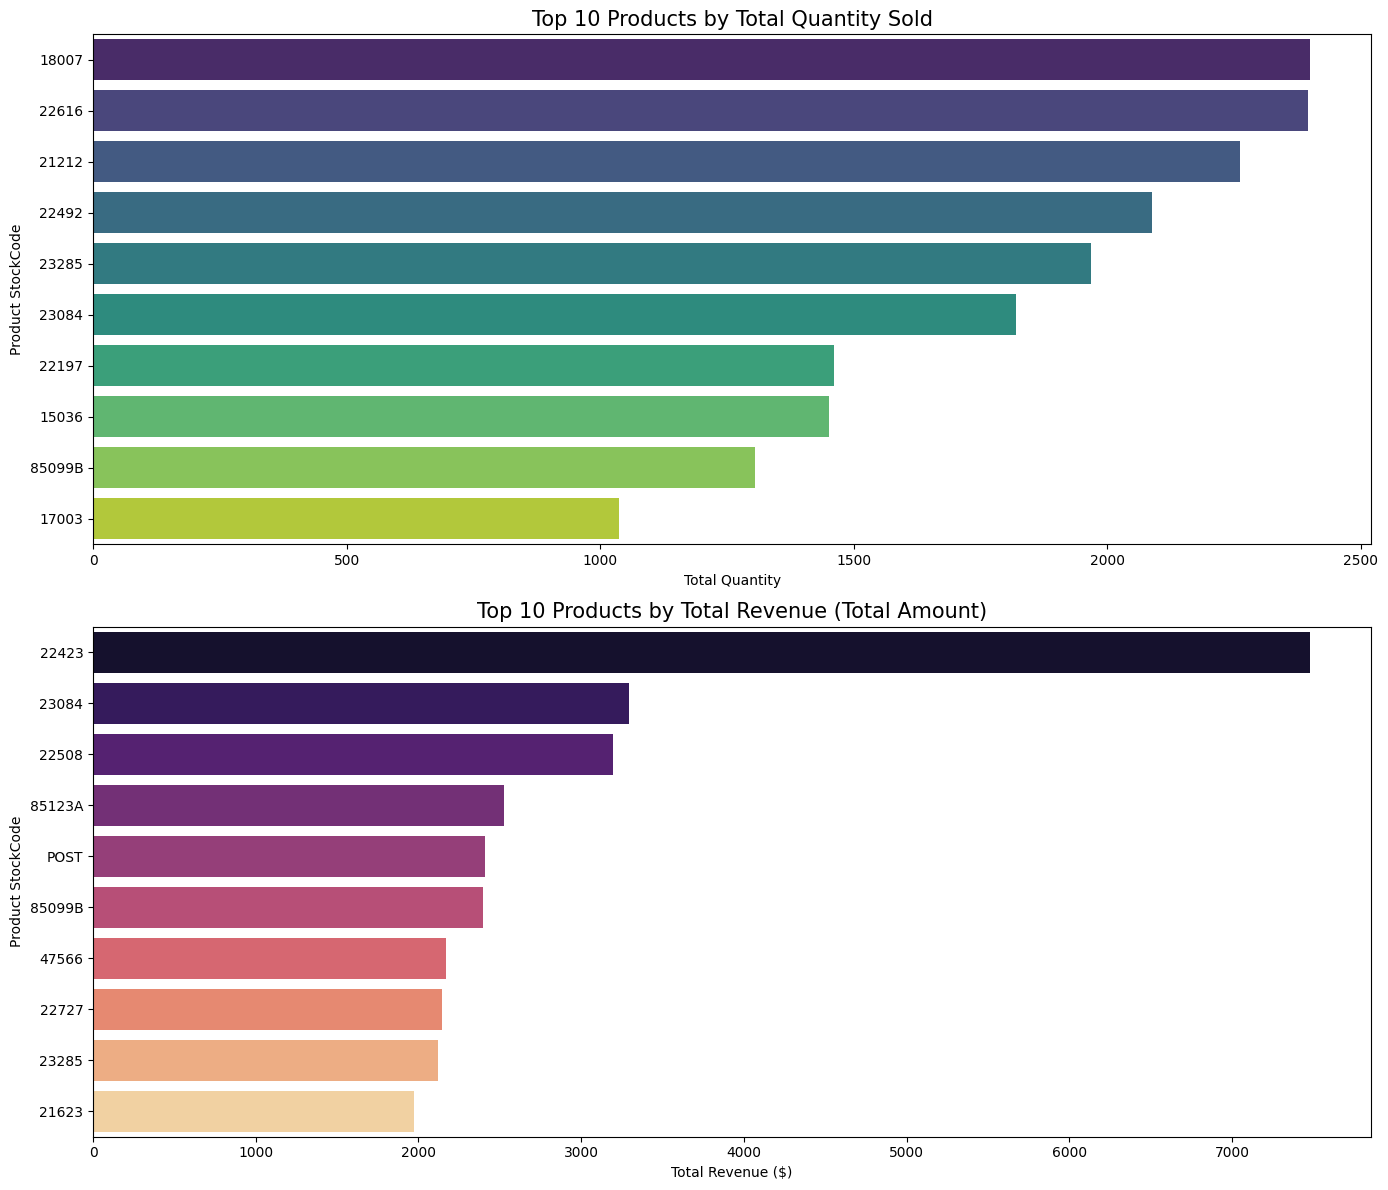

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# grouping products by stock code to further analysis
product_analysis = df.groupby('StockCode').agg({
    'Quantity': 'sum',
    'TotalAmount': 'sum'
}).reset_index()

# top 10 items by quantity
top_qty = product_analysis.sort_values(by='Quantity', ascending=False).head(10)

# top 10 items by revenue
top_rev = product_analysis.sort_values(by='TotalAmount', ascending=False).head(10)


plt.figure(figsize=(14, 12))

# Plot 1: top 10 items by quantity
plt.subplot(2, 1, 1)
sns.barplot(data=top_qty, x='Quantity', y='StockCode', palette='viridis')
plt.title('Top 10 Products by Total Quantity Sold', fontsize=15)
plt.xlabel('Total Quantity')
plt.ylabel('Product StockCode')

# Plot 2: top 10 items by revenue
plt.subplot(2, 1, 2)
sns.barplot(data=top_rev, x='TotalAmount', y='StockCode', palette='magma')
plt.title('Top 10 Products by Total Revenue (Total Amount)', fontsize=15)
plt.xlabel('Total Revenue ($)')
plt.ylabel('Product StockCode')

plt.tight_layout()
plt.show()

/tmp/ipykernel_2627/2645049066.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=bottom_qty, x='Quantity', y='StockCode', palette='viridis')
/tmp/ipykernel_2627/2645049066.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=bottom_rev, x='TotalAmount', y='StockCode', palette='magma')


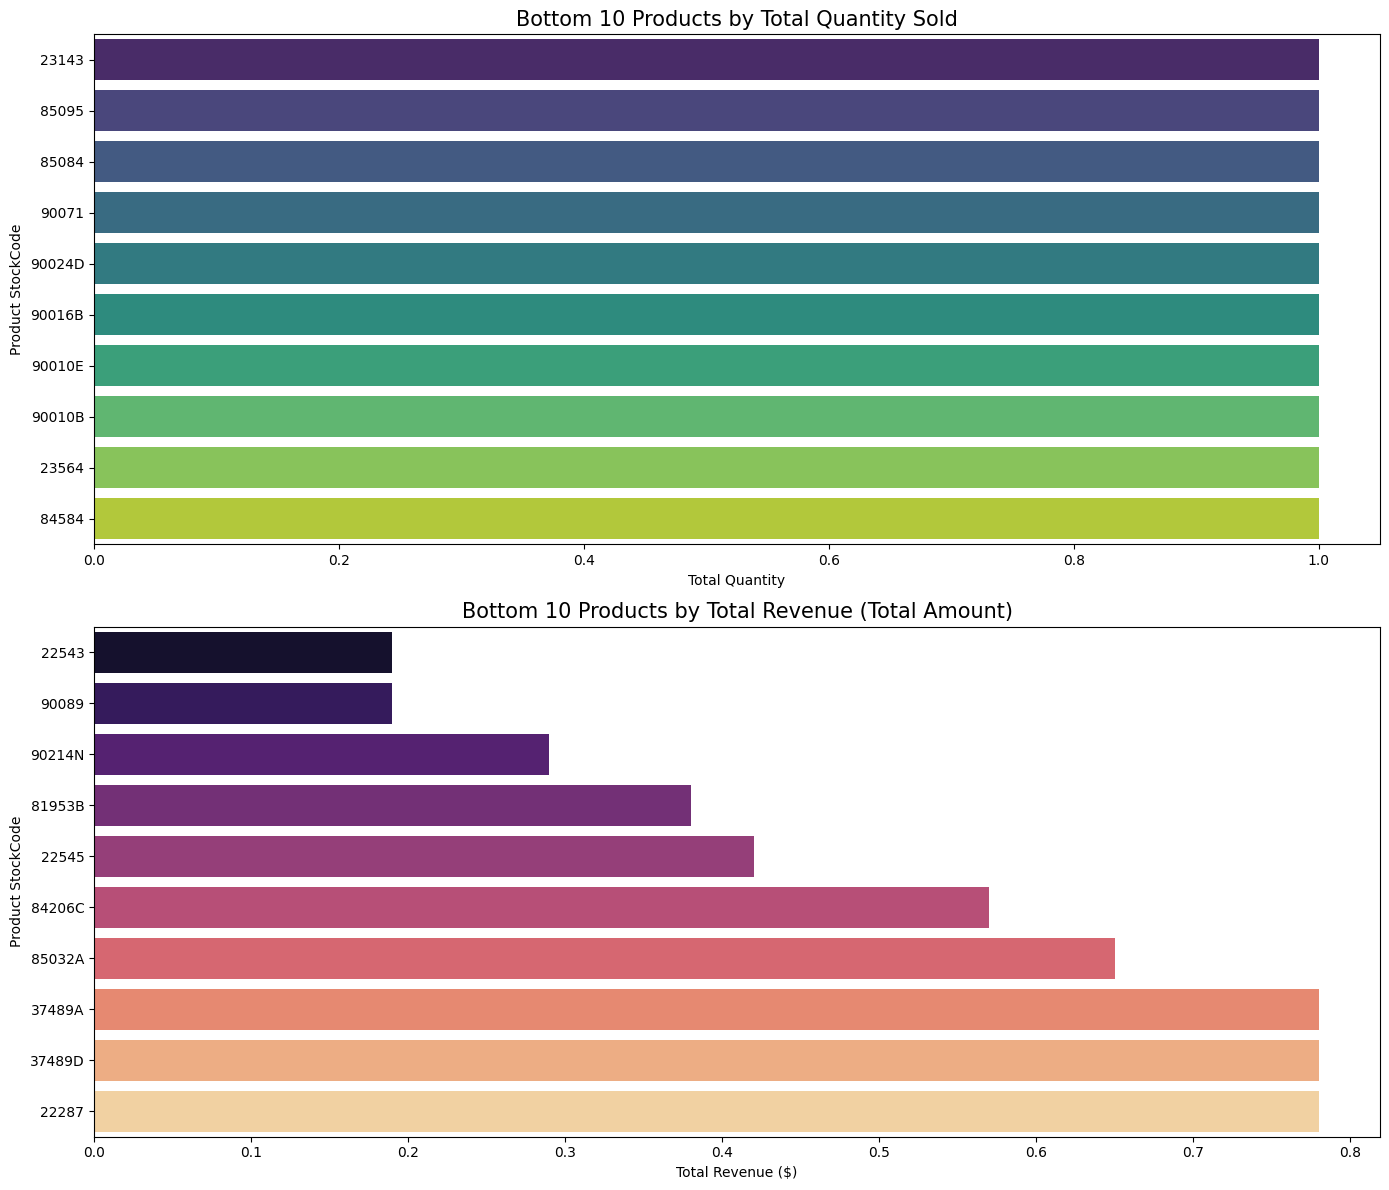

In [17]:
# bottom 10 items by quantity
bottom_qty = product_analysis.sort_values(by='Quantity', ascending=True).head(10)

# bottom 10 items by revenue
bottom_rev = product_analysis.sort_values(by='TotalAmount', ascending=True).head(10)


plt.figure(figsize=(14, 12))

# Plot 1: bottom 10 items by quantity
plt.subplot(2, 1, 1)
sns.barplot(data=bottom_qty, x='Quantity', y='StockCode', palette='viridis')
plt.title('Bottom 10 Products by Total Quantity Sold', fontsize=15)
plt.xlabel('Total Quantity')
plt.ylabel('Product StockCode')

# Plot 2: bottom 10 items by revenue
plt.subplot(2, 1, 2)
sns.barplot(data=bottom_rev, x='TotalAmount', y='StockCode', palette='magma')
plt.title('Bottom 10 Products by Total Revenue (Total Amount)', fontsize=15)
plt.xlabel('Total Revenue ($)')
plt.ylabel('Product StockCode')

plt.tight_layout()
plt.show()

### Result & Interpretation:
We can see that the items that are the most sold in quantity are not necesseraily the ones generating the most reveune

## 5.2 Analyze Sale Trends

### Question:
What are the highest and lowest selling months?

### Analysis:
I will group data by yearmonth

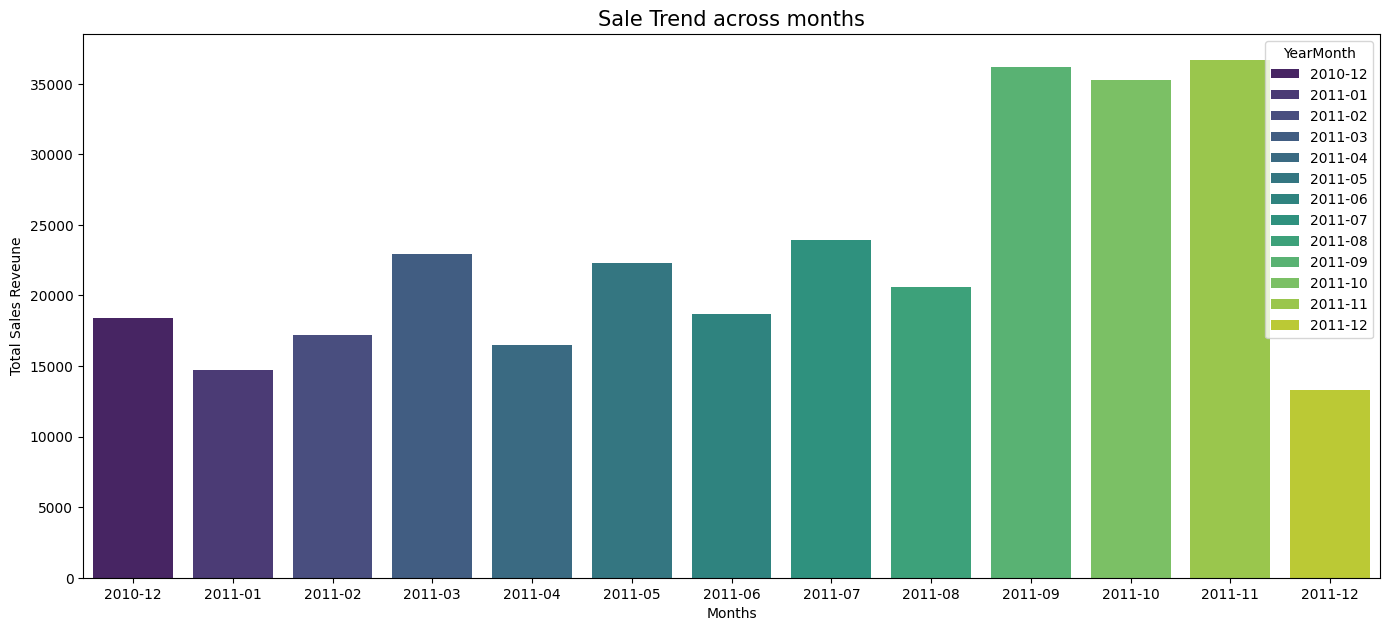

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# grouping products by YearMonth to analayze year month trend
product_analysis_yearmonth = df.groupby('YearMonth')

plt.figure(figsize=(14, 12))

# Plot : Histogram of sales across months
plt.subplot(2, 1, 1)
#aggregate months by total amount to analyze sale trends
sales_trend = product_analysis_yearmonth.agg({'TotalAmount': 'sum'}).reset_index()
sns.barplot(data=sales_trend, x='YearMonth', y='TotalAmount', hue='YearMonth', palette='viridis', legend=True)

plt.title('Sale Trend across months', fontsize=15)
plt.ylabel('Total Sales Reveune')
plt.xlabel('Months')

plt.tight_layout()
plt.show()

### Result & Interpretation:
We can see that the the peak of sales where at Sep-Nov and the bottom was at Jan

## 5.3 Analyze Pricing Distribution over sales

### Question:
What is the average price most people buy at?

### Analysis:
I will show the histogram for the frequency of sales across different unit prices

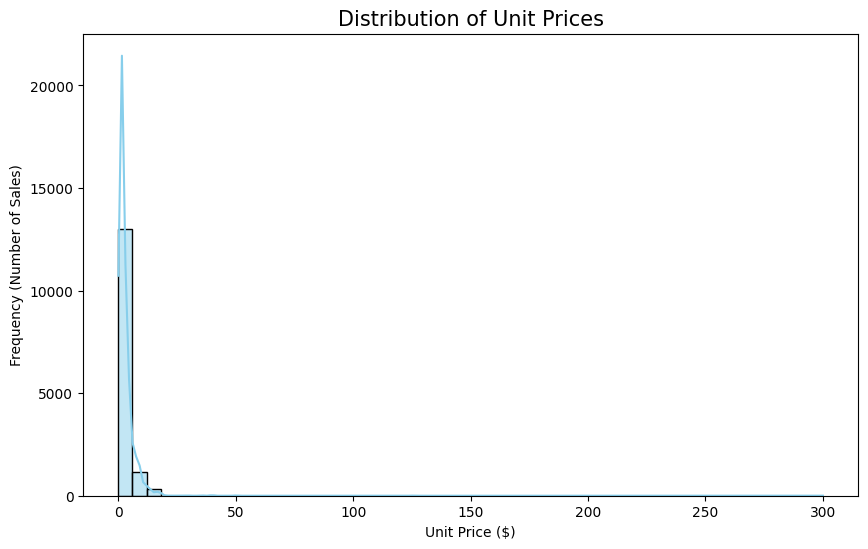

Price Statistics:


,UnitPrice
count,14526.000000
mean,2.998048
std,5.628479
min,0.040000
25%,1.250000
50%,1.950000
75%,3.750000
max,300.000000


In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# distribution of UnitPrice
plt.figure(figsize=(10, 6))
sns.histplot(df['UnitPrice'], bins=50, kde=True, color='skyblue')

plt.title('Distribution of Unit Prices', fontsize=15)
plt.xlabel('Unit Price ($)')
plt.ylabel('Frequency (Number of Sales)')
plt.show()

# check the statistics to see the exact numbers
print("Price Statistics:")
display(df['UnitPrice'].describe())

### Result & Interpretation:
we can see that items higher than 20 are rarely being bought


## 5.4 Analyze Geographic Sales

### Question:
What country has the most amouont of sales and what country has the least amount of sales ?

### Analysis:
I will show the histogram for the frequency of sales across different countries

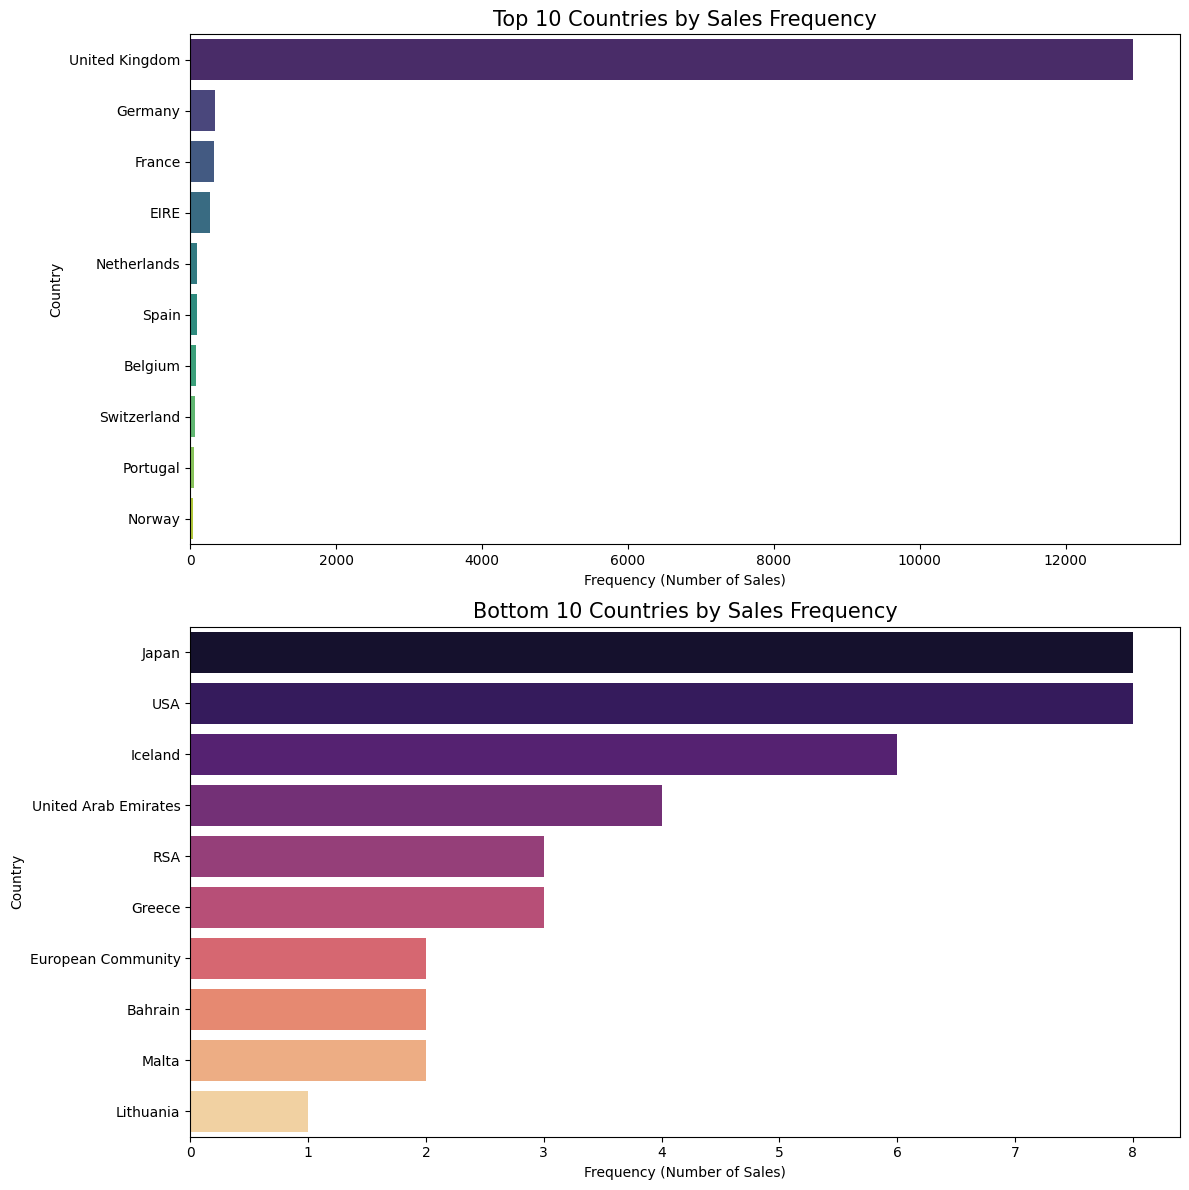

Country Statistics:


,Country
count,14526
unique,33
top,United Kingdom
freq,12921


In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

plt.figure(figsize=(12, 12))

country_counts = df['Country'].value_counts()

# showing only the top 10 countries and then the bottom 10 countries
top_10 = country_counts.head(10)
bottom_10 = country_counts.tail(10)

# Plot 1: Top 10
plt.subplot(2, 1, 1)
sns.barplot(x=top_10.values, y=top_10.index, palette='viridis', hue=top_10.index, legend=False)
plt.title('Top 10 Countries by Sales Frequency', fontsize=15)
plt.xlabel('Frequency (Number of Sales)')
plt.ylabel('Country')

# Plot 2: Bottom 10
plt.subplot(2, 1, 2)
sns.barplot(x=bottom_10.values, y=bottom_10.index, palette='magma', hue=bottom_10.index, legend=False)
plt.title('Bottom 10 Countries by Sales Frequency', fontsize=15)
plt.xlabel('Frequency (Number of Sales)')
plt.ylabel('Country')

plt.tight_layout()
plt.show()

# check the statistics to see the exact numbers
print("Country Statistics:")
display(df['Country'].describe())

### Result & Interpretation:
we can see that United Kingdom has signinficantly higher sales and Japan, Usa and Iceland has less sales than the other countries


## 5.5 Analyze Popular Items by country

### Question:
In the top performing countries what are the poplar items being sold?

### Analysis:
I will group the Sales by country and choose the top 10 countries then choose the top 3 best selling items for each country

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

#I will group the Sales by country and choose the top 10 countries
# then choose the top 3 best selling items for each country

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd


country_counts = df['Country'].value_counts()

top_10 = country_counts.head(10)

df_filtered = df[df['Country'].isin(top_10.index)]

product_analysis = df_filtered.groupby(['Country', 'StockCode']).agg({
    'Quantity': 'sum',
    'TotalAmount': 'sum'
}).reset_index()

top_3_products = product_analysis.groupby('Country').apply(lambda x: x.nlargest(3, 'Quantity')).reset_index(drop=True)


top_3_products

/tmp/ipykernel_2627/2999846531.py:24: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  top_3_products = product_analysis.groupby('Country').apply(lambda x: x.nlargest(3, 'Quantity')).reset_index(drop=True)


,Country,StockCode,Quantity,TotalAmount
0,Belgium,23310,180,64.80
1,Belgium,21212,48,26.40
2,Belgium,22661,40,34.00
3,EIRE,22910,206,527.70
4,EIRE,22045,200,72.00
5,EIRE,21166,144,266.40
6,France,23203,320,578.60
7,France,21212,144,63.60
8,France,22492,144,93.60
9,Germany,23293,128,92.16


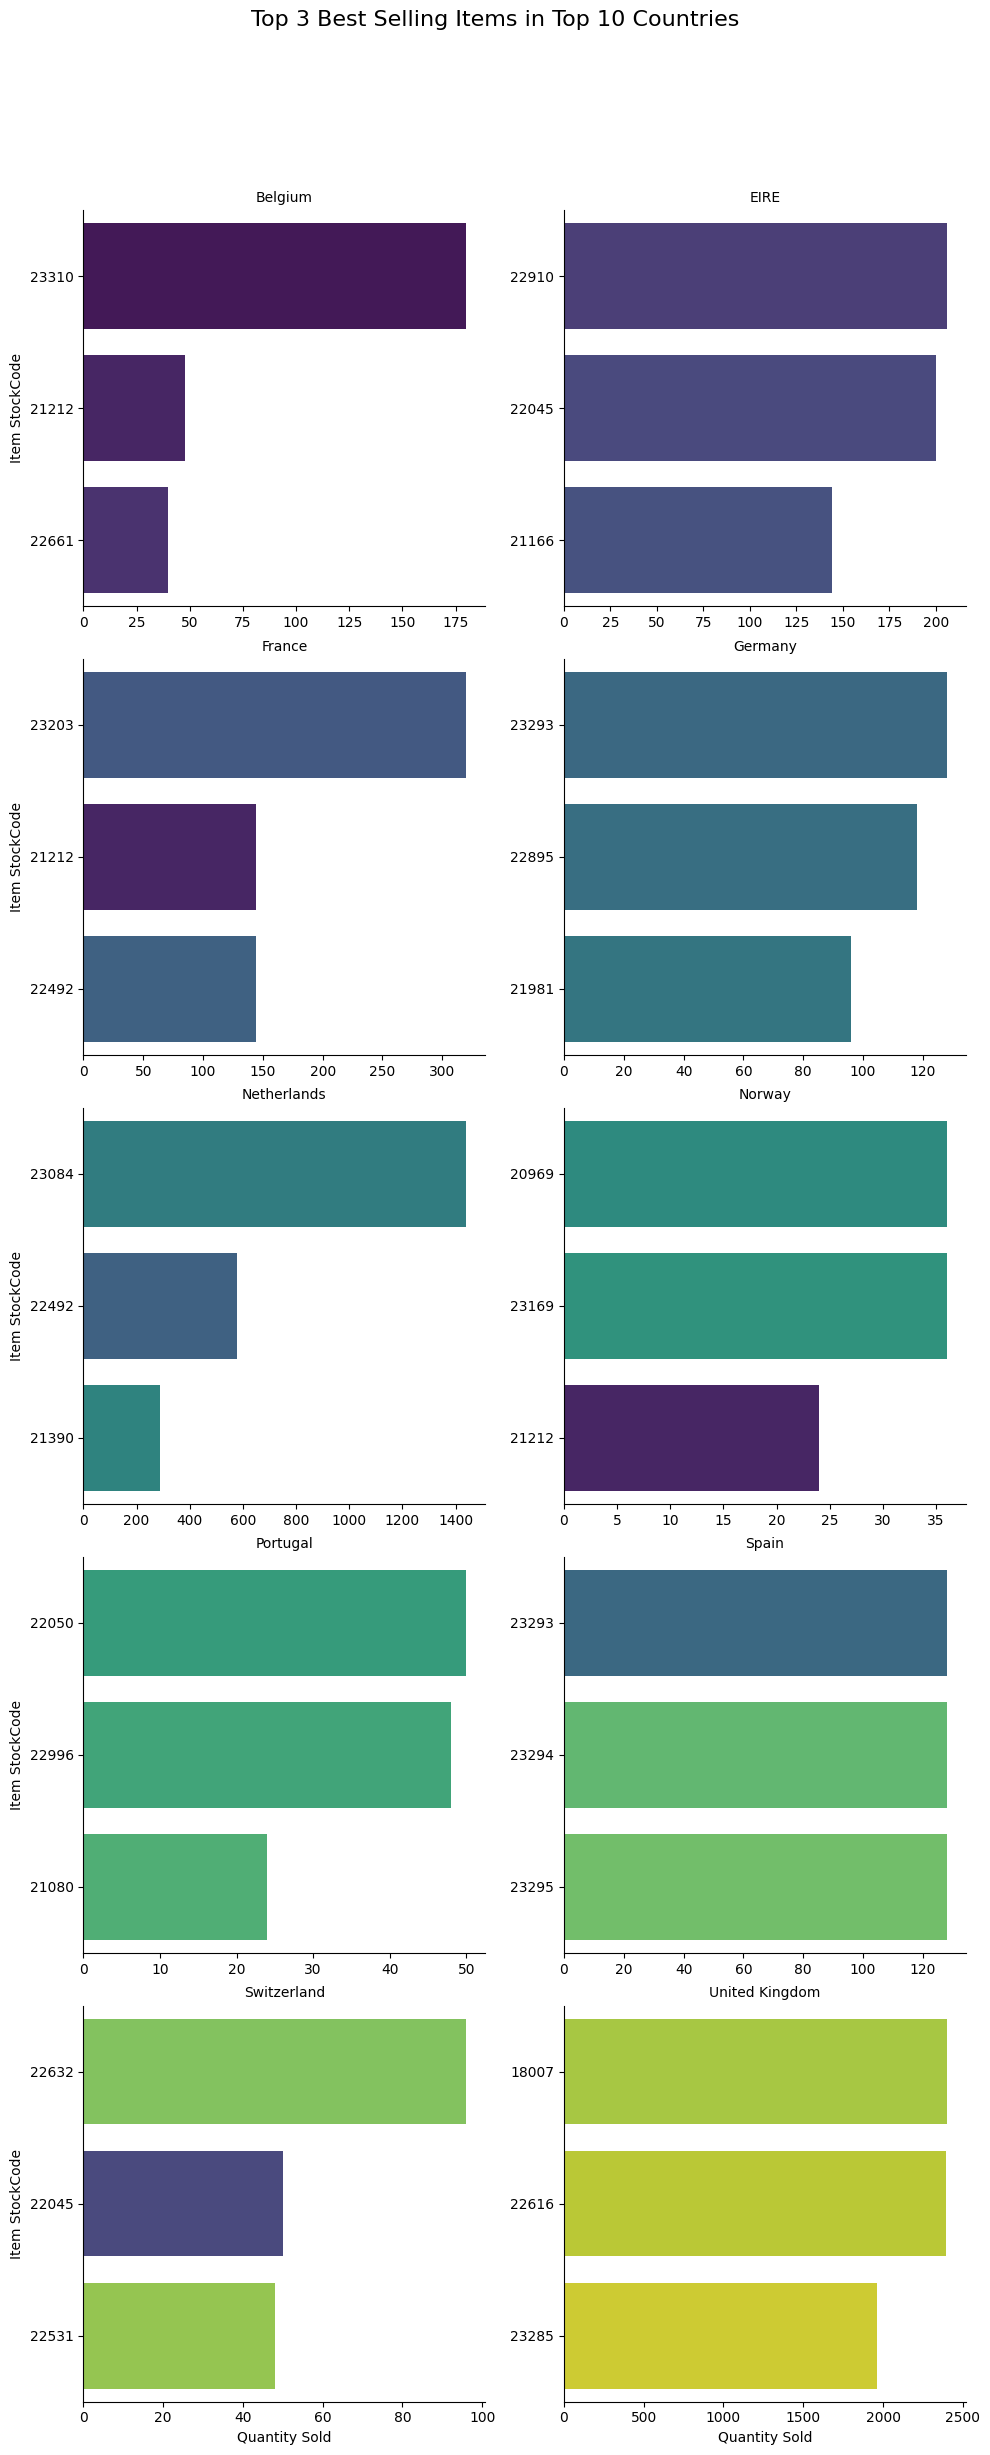

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

# catplot to create a grid of charts, one for each country
g = sns.catplot(
    data=top_3_products,
    kind="bar",
    x="Quantity",
    y="StockCode",
    col="Country",
    col_wrap=2,  # 2 charts per row
    sharey=False, # Important: each country has different items
    sharex=False,
    palette="viridis",
    hue="StockCode"
)

g.set_titles("{col_name}")
g.set_axis_labels("Quantity Sold", "Item StockCode")
plt.subplots_adjust(top=0.9)
g.fig.suptitle('Top 3 Best Selling Items in Top 10 Countries', fontsize=16)

plt.show()

### Result & Interpretation:
we can see that United Kingdom is dominated by StockCodes 18007 and 22616, Netherlands shows a very high volume for item 23084 compared to other countries and some items like 21212 appear in the top 3 for multiple countries (Belgium, France, Norway) while others are unique to specifc regions.

## 5.6 Finding Something Unexpected
United Kingdom has the highest amount of sales to other countries by a huge margin, but still Netherlands has a very high sale amount for a specific product (23084) which means the Netherlands might have more wholesale/bulk buyers rather than individual retail shoppers.

# 6. Key Insights

Based on my analysis of the charts, here are the top 5 key findings:

### 1. Best Sellers vs. Money Makers
* **What I found:** The products with the highest quantity sold are not the ones making the most revenue.
* **Why it matters:** Just because an item sells in high numbers doesn't mean it makes the most money. We should focus on high-value items, not just high quantities.

### 2. High Holiday Peak
* **What I found:** Sales spike really high from September to November, and drop to the lowest point in January.
* **Why it matters:** This is a seasonal market. We need to prepare and stock up on products right before September to make the most of this holiday surge.

### 3. 20 Price Threshold
* **What I found:** People rarely buy items that cost more than 20.
* **Why it matters:** Our shoppers are very price-sensitive. Keeping our inventory priced under 20 is key to getting quick and easy sales.

### 4. UK Sales Dominance
* **What I found:** The UK has way more sales and transactions than any other country in the list.
* **Why it matters:** Relying mostly on the UK is risky. We need to branch out and do more promotions in other countries like Japan or the USA where sales are low.

### 5. Bulk Buyers in Netherlands
* **What I found:** Even though the UK has more orders overall, the Netherlands orders huge quantities of a specific product (23084).
* **Why it matters:** This means the Netherlands has big wholesale/bulk buyers rather than normal retail shoppers. We should create wholesale deals specifically for them.

# 7. Recommendations

1. **Expand outside the UK:** Run more ads and promotions targeting other countries to grow our smaller markets.
2. **Focus on cheaper products:** Bring in more products priced under $20 since that is what customers buy the most.
3. **Push ads during Sep-Nov:** Double down on marketing during our peak sales window to maximize holiday profits.

In [23]:
#exporting processed data
df.to_csv('online_retail_task2_students_processed3.csv', index=False)


# 8. Conclusion

This retail sales analysis reveals a highly seasonal, price-sensitive market dominated by the UK. By focusing product sourcing on items under $20, preparing stock for the Q3/Q4 peak, and targeting emerging wholesale buyers in regions like the Netherlands, the company can efficiently scale its revenues and optimize operations.